# 03. Modelagem e avaliação

**Objetivo:** ver se um modelo prevê melhor quem vai recomprar do que uma regra simples.

**Passos:** (1) ler as tabelas, (2) definir comparações simples, (3) treinar dois modelos, (4) avaliar no período de teste, (5) ver o valor para o negócio.

### Glossário rápido

- **ROC-AUC:** dá uma nota de 0 a 1. Escolhendo um cliente que recomprou e um que não recomprou, é a chance de o modelo dar nota maior ao que recomprou. **0,5 é o mesmo que chute.**
- **PR-AUC:** mede quão "limpa" é a lista dos clientes mais bem avaliados. O ponto de comparação é a própria taxa de recompra.
- **Lift:** quantas vezes a taxa de recompra de um grupo é maior que a média geral.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

train_data = pd.read_csv('../data/processed/treino.csv', index_col=0)
test_data = pd.read_csv('../data/processed/teste.csv', index_col=0)
print(f'Treino: {len(train_data):,} clientes | Teste: {len(test_data):,} clientes')

Treino: 2,780 clientes | Teste: 3,359 clientes


## 1. Preparar as variáveis

Quantidade e gasto têm valores muito altos para poucos clientes. O `log1p` (logaritmo de 1 + valor) "achata" essa diferença e ajuda os modelos. O alvo é o que queremos prever; o resto são as variáveis.

In [13]:
feature_columns = [
    'recency_days',
    'invoice_count',
    'total_quantity',
    'total_spend'
]

def prepare_features(customer_table):
    X = customer_table[feature_columns].copy()

    X['total_quantity'] = np.log1p(X['total_quantity'])
    X['total_spend'] = np.log1p(X['total_spend'])

    return X

X_train = prepare_features(train_data)
y_train = train_data['repurchased']

X_test = prepare_features(test_data)
y_test = test_data['repurchased']

## 2. Comparações simples (o que o modelo precisa superar)

Um modelo só tem valor se ganhar de regras simples que qualquer pessoa poderia usar:

- **Sempre dizer "vai recomprar":** acerta tanto quanto a taxa de recompra do teste.
- **Regra "quem mais comprou":** a nota do cliente é o número de faturas dele.

In [14]:
# Calcular taxa de recompra
repurchase_rate = y_test.mean()

print(f'Prever que todos os clientes vão recomprar '
      f'gera uma acurácia de {repurchase_rate:.1%} no teste.')

model_results = []

# Comparar modelos usando ROC-AUC e PR-AUC
def evaluate_model(model_name, customer_scores):
    model_results.append({
        'Model': model_name,
        'ROC-AUC': roc_auc_score(y_test, customer_scores),
        'PR-AUC': average_precision_score(y_test, customer_scores)
    })

# Regra de referência: clientes com mais faturas recebem pontuações maiores
evaluate_model(
    'Baseline - Invoice Count',
    test_data['invoice_count']
)

Prever que todos os clientes vão recomprar gera uma acurácia de 58.1% no teste.


## 3. Treinar os dois modelos

- **Regressão Logística:** modelo simples; combina as variáveis em uma conta e devolve uma probabilidade. Exige variáveis na mesma escala (`StandardScaler`).
- **Random Forest:** muitas árvores de decisão votando juntas; captura relações mais complexas.

Os dois aprendem **só com a tabela de treino**.

In [15]:
# Treinar o modelo de Regressão Logística
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

# Treinar o modelo Random Forest
random_forest_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

# Calcular as pontuações de recompra
logistic_scores = logistic_model.predict_proba(X_test)[:, 1]
random_forest_scores = random_forest_model.predict_proba(X_test)[:, 1]

# Registrar os resultados dos modelos
evaluate_model('Logistic Regression', logistic_scores)
evaluate_model('Random Forest', random_forest_scores)

## 4. Avaliar no período de teste

Agora usamos o futuro, que os modelos nunca viram. Cada modelo devolve a probabilidade de recompra de cada cliente.

In [16]:
# Criar a tabela de comparação
model_results = pd.DataFrame(model_results).round(3)

display(model_results)

# Salvar os resultados em um arquivo CSV
Path('../reports').mkdir(exist_ok=True)

model_results.to_csv(
    '../reports/model_results.csv',
    index=False
)

,Model,ROC-AUC,PR-AUC
0,Baseline - Invoice Count,0.713,0.758
1,Logistic Regression,0.729,0.793
2,Random Forest,0.715,0.791


**Como ler:** o ROC-AUC de cada modelo deve ser comparado com o da regra simples e com 0,5 (chute). Com poucos milhares de clientes no teste, **diferenças menores que cerca de 0,02 entre dois modelos devem ser tratadas como empate**, porque podem ser só ruído da amostra. Isso é uma regra prática, não um teste estatístico.

In [17]:
best_model_name = 'Regressão Logística' if roc_auc_score(y_test, logistic_scores) >= roc_auc_score(y_test, random_forest_scores) else 'Random Forest'
best_scores = logistic_scores if best_model_name == 'Regressão Logística' else random_forest_scores

model_auc = roc_auc_score(y_test, best_scores)
baseline_auc = roc_auc_score(y_test, test_data['invoice_count'])
auc_difference = model_auc - baseline_auc
print(f'Melhor modelo: {best_model_name} (ROC-AUC {model_auc:.3f})')
print(f'Regra "quem mais comprou": ROC-AUC {baseline_auc:.3f}')
print(f'Diferença: {auc_difference:+.3f}', '-> parece melhor que a regra' if auc_difference > 0.02 else '-> empate técnico: o modelo não se mostrou melhor que a regra simples')

Melhor modelo: Regressão Logística (ROC-AUC 0.729)
Regra "quem mais comprou": ROC-AUC 0.713
Diferença: +0.016 -> empate técnico: o modelo não se mostrou melhor que a regra simples


## 5. O valor para o negócio: a tabela de lift

Imagine que o time de marketing só pode contatar parte dos clientes. Ordenamos os clientes pela nota do modelo e dividimos em 10 grupos de mesmo tamanho (**decis**). O decil 1 tem os clientes que o modelo considera mais propensos a recomprar.

Se o modelo é útil, a taxa de recompra deve **cair** do decil 1 para o 10.

,customers,repurchases,repurchase_rate,lift_table,cumulative_capture
decil,,,,,
1,336,307,0.914,1.573,0.157
2,336,277,0.824,1.419,0.299
3,336,253,0.753,1.296,0.429
4,336,216,0.643,1.107,0.540
5,336,205,0.610,1.050,0.645
6,335,172,0.513,0.884,0.733
7,336,156,0.464,0.799,0.813
8,336,150,0.446,0.769,0.890
9,336,108,0.321,0.553,0.945


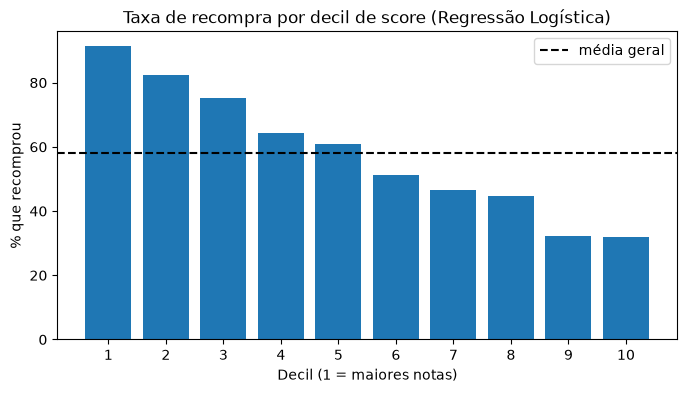

In [18]:
lift_data = pd.DataFrame({'real': y_test.values, 'score': best_scores})
lift_data['decil'] = pd.qcut(lift_data['score'].rank(method='first', ascending=False), 10, labels=range(1, 11))

lift_table = lift_data.groupby('decil', observed=True)['real'].agg(customers='size', repurchases='sum', repurchase_rate='mean')
lift_table['lift_table'] = lift_table['repurchase_rate'] / y_test.mean()
lift_table['cumulative_capture'] = lift_table['repurchases'].cumsum() / lift_table['repurchases'].sum()
display(lift_table.round(3))

plt.figure(figsize=(8, 4))
plt.bar(lift_table.index.astype(int), lift_table['repurchase_rate'] * 100)
plt.axhline(y_test.mean() * 100, color='black', linestyle='--', label='média geral')
plt.title(f'Taxa de recompra por decil de score ({best_model_name})')
plt.xlabel('Decil (1 = maiores notas)')
plt.ylabel('% que recomprou')
plt.xticks(range(1, 11))
plt.legend()
plt.show()

**Como ler:** a coluna `captura_acumulada` diz que parte de todos os recompradores já foi alcançada ao contatar os decis até aquela linha. Se o decil 2 mostra, por exemplo, 30%, contatar só 20% dos clientes alcançaria 30% dos recompradores. Sem modelo, seriam 20%.

## 6. Quais variáveis mais pesam?

In [19]:
feature_importance = pd.DataFrame({
    'variável': feature_columns,
    'Regressão Logística (coeficiente)': logistic_model.named_steps['modelo'].coef_[0],
    'Random Forest (importância)': random_forest_model.feature_importances_,
}).round(3)
display(feature_importance)

KeyError: 'modelo'

Na Regressão Logística, o sinal do coeficiente indica o sentido: positivo aumenta a chance de recompra, negativo diminui (as variáveis estão padronizadas, então os tamanhos são comparáveis). Esses números mostram **associação**, não que uma variável cause a recompra.

## Conclusões

_Escreva aqui, com os números acima:_

1. _O melhor modelo superou a regra "quem mais comprou"? Por quanto?_
2. _A diferença entre os dois modelos é maior que ~0,02?_
3. _O que a tabela de lift indica para uma campanha?_
4. _Quais limitações pesam (treino e teste em épocas diferentes, só uma loja, só 4 variáveis)?_

_Se o modelo não superou a regra simples, escreva isso: é um resultado válido e honesto._